# Diabetes risk model (Pima Indians Diabetes)

Source: OpenML dataset 37 (copy of the original UCI file). 768 women of Pima heritage, aged 21+.
MedTrail uses 4 inputs a patient's reports can provide: Glucose, BloodPressure, BMI, Age.

| Column | Meaning |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose 2 hours after a glucose tolerance test (mg/dL) |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skin fold thickness (mm) |
| Insulin | 2-hour serum insulin (µU/mL) |
| BMI | Body mass index: weight (kg) / height (m)² |
| DiabetesPedigreeFunction | Family-history score |
| Age | Age in years |
| **Outcome** | **Target: 1 = diabetes, 0 = no diabetes** |

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project folder: the nearest folder above this notebook that has requirements.txt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
print("Project folder:", ROOT)

Project folder: c:\Users\Amupam Raj\projects\medtrail-ai


In [5]:
df = pd.read_csv(ROOT / "datasets" / "raw" / "diabetes" / "diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.8,3.4,0.0,1.0,3.0,6.0,17.0
Glucose,768.0,120.9,32.0,0.0,99.0,117.0,140.2,199.0
BloodPressure,768.0,69.1,19.4,0.0,62.0,72.0,80.0,122.0
SkinThickness,768.0,20.5,16.0,0.0,0.0,23.0,32.0,99.0
Insulin,768.0,79.8,115.2,0.0,0.0,30.5,127.2,846.0
BMI,768.0,32.0,7.9,0.0,27.3,32.0,36.6,67.1
DiabetesPedigreeFunction,768.0,0.5,0.3,0.1,0.2,0.4,0.6,2.4
Age,768.0,33.2,11.8,21.0,24.0,29.0,41.0,81.0
Outcome,768.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0


In [7]:
ZERO_MEANS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[ZERO_MEANS_MISSING] = df[ZERO_MEANS_MISSING].replace(0, np.nan)

missing = df.isna().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)})

,missing,percent
Pregnancies,0,0.0
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4
DiabetesPedigreeFunction,0,0.0
Age,0,0.0
Outcome,0,0.0


In [8]:
counts = df["Outcome"].value_counts()
print(counts)
print(f"Diabetes rate: {df['Outcome'].mean():.1%}")
print(f"Accuracy if we always guess 'no diabetes': {counts[0] / len(df):.1%}")

Outcome
0    500
1    268
Name: count, dtype: int64
Diabetes rate: 34.9%
Accuracy if we always guess 'no diabetes': 65.1%


Median value in each group:
         Glucose  BloodPressure   BMI   Age
Outcome                                    
0          107.0           70.0  30.1  27.0
1          140.0           74.5  34.3  36.0

Correlation with Outcome (higher = more related):
Glucose          0.49
BMI              0.31
Age              0.24
BloodPressure    0.17
Name: Outcome, dtype: float64


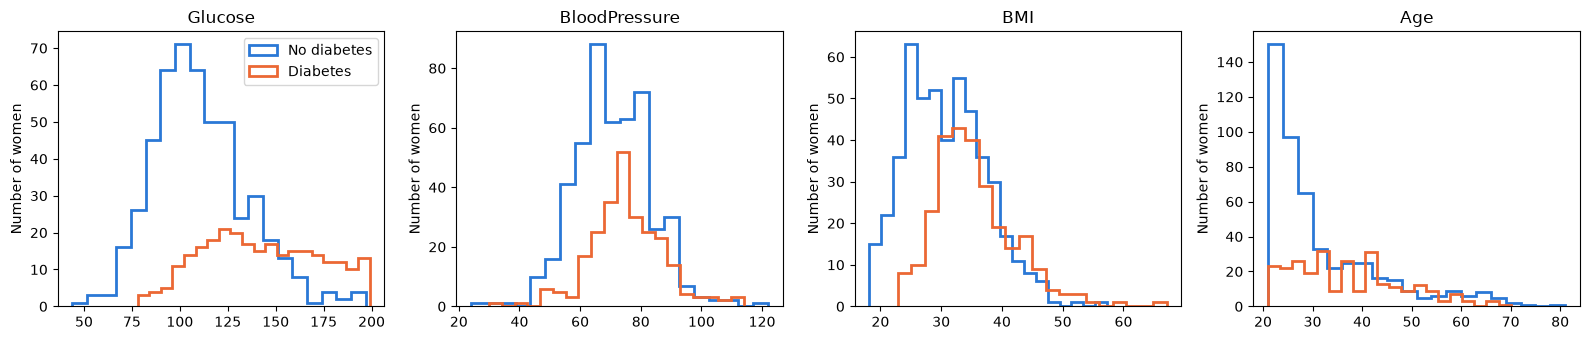

In [9]:
FEATURES = ["Glucose", "BloodPressure", "BMI", "Age"]

print("Median value in each group:")
print(df.groupby("Outcome")[FEATURES].median().round(1))
print("\nCorrelation with Outcome (higher = more related):")
print(df[FEATURES + ["Outcome"]].corr()["Outcome"].drop("Outcome").round(2).sort_values(ascending=False))

COLORS = {0: "#2a78d6", 1: "#eb6834"}
LABELS = {0: "No diabetes", 1: "Diabetes"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, FEATURES):
    for outcome in [0, 1]:
        values = df.loc[df["Outcome"] == outcome, col].dropna()
        ax.hist(values, bins=20, histtype="step", linewidth=2, color=COLORS[outcome], label=LABELS[outcome])
    ax.set_title(col)
    ax.set_ylabel("Number of women")
axes[0].legend()
plt.tight_layout()
plt.show()

## Train, compare and save the model
1. Split the data: 80% training (614 patients), 20% test (154). The test set is used only once, at the end.
2. Compare 3 models with 5-fold cross-validation on the training set only.
3. Test the best model once and turn its probabilities into Low / Moderate / High risk.
4. Save the model pipeline and its results.

In [10]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Training patients:", len(X_train), "| Test patients:", len(X_test))
print(f"Diabetes rate - train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Training patients: 614 | Test patients: 154
Diabetes rate - train: 34.9% | test: 35.1%


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Random Forest": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)),
    ]),
    "XGBoost": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                eval_metric="logloss", random_state=42)),
    ]),
}
print("Models ready:", list(models))

Models ready: ['Logistic Regression', 'Random Forest', 'XGBoost']


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
METRICS = ["roc_auc", "accuracy", "precision", "recall", "f1"]

rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICS)
    row = {"model": name}
    for m in METRICS:
        row[m] = scores[f"test_{m}"].mean()
    row["roc_auc_spread"] = scores["test_roc_auc"].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False).round(3)
cv_results

,roc_auc,accuracy,precision,recall,f1,roc_auc_spread
model,,,,,,
Logistic Regression,0.834,0.778,0.741,0.565,0.641,0.020
Random Forest,0.820,0.762,0.691,0.584,0.632,0.035
XGBoost,0.814,0.749,0.660,0.589,0.621,0.034


Best model (highest cross-validated ROC-AUC): Logistic Regression
Results on the 154 test patients (used only once):
  roc_auc   0.787
  accuracy  0.708
  precision 0.596
  recall    0.519
  f1        0.554


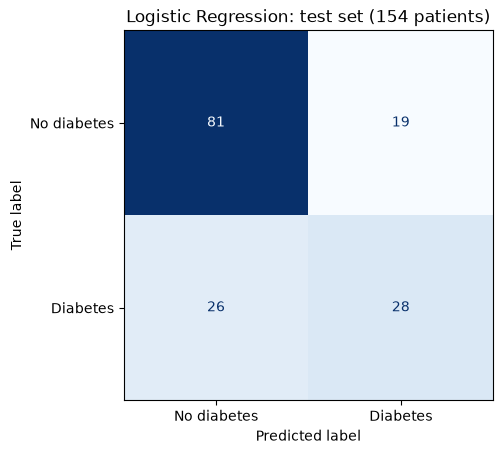

In [13]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)

best_name = cv_results.index[0]
best_model = models[best_name]
best_model.fit(X_train, y_train)

proba = best_model.predict_proba(X_test)[:, 1]   # probability of diabetes for each test patient
pred = (proba >= 0.5).astype(int)                # yes/no using a 0.5 cut-off

test_metrics = {
    "roc_auc": roc_auc_score(y_test, proba),
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
}
print("Best model (highest cross-validated ROC-AUC):", best_name)
print("Results on the 154 test patients (used only once):")
for name, value in test_metrics.items():
    print(f"  {name:<10}{value:.3f}")

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{best_name}: test set ({len(y_test)} patients)")
plt.show()

In [14]:
def risk_level(probability):
    if probability < 0.30:
        return "Low"
    if probability < 0.60:
        return "Moderate"
    return "High"

check = pd.DataFrame({"risk_level": [risk_level(p) for p in proba], "had_diabetes": y_test.values})
risk_table = check.groupby("risk_level")["had_diabetes"].agg(patients="size", actually_had_diabetes="mean")
risk_table = risk_table.reindex(["Low", "Moderate", "High"])
risk_table["actually_had_diabetes"] = (risk_table["actually_had_diabetes"] * 100).round().astype(int).astype(str) + "%"
risk_table

,patients,actually_had_diabetes
risk_level,,
Low,82,17%
Moderate,36,42%
High,36,69%


In [15]:
import json
import platform
from datetime import date

import joblib
import sklearn
import xgboost

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(best_model, MODELS_DIR / "diabetes_pipeline.joblib")

info = {
    "disease": "diabetes",
    "model": best_name,
    "features": FEATURES,
    "inputs_must_be_above_zero": FEATURES,
    "risk_levels": {"Low": "below 0.30", "Moderate": "0.30 to below 0.60", "High": "0.60 and above"},
    "dataset": "Pima Indians Diabetes, OpenML dataset 37 (original UCI file), 768 rows",
    "split": "80/20 stratified, random_state=42: 614 train, 154 test",
    "cross_validation": "5-fold stratified on the 614 training patients",
    "cv_results": cv_results.reset_index().to_dict(orient="records"),
    "test_metrics": {name: round(value, 3) for name, value in test_metrics.items()},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "xgboost": xgboost.__version__},
    "trained_on": str(date.today()),
    "note": "Screening estimate from a small public dataset. Not a diagnosis.",
}
(MODELS_DIR / "diabetes_metrics.json").write_text(json.dumps(info, indent=2))
print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()))

Saved: ['diabetes_metrics.json', 'diabetes_pipeline.joblib']


In [16]:
loaded = joblib.load(MODELS_DIR / "diabetes_pipeline.joblib")

sample = pd.DataFrame([{"Glucose": 165, "BloodPressure": 78, "BMI": 33.5, "Age": 52}])
p = loaded.predict_proba(sample)[0, 1]
print(f"Sample patient: probability {p:.2f} -> {risk_level(p)} risk")

healthy = pd.DataFrame([{"Glucose": 95, "BloodPressure": 70, "BMI": 23.0, "Age": 25}])
p2 = loaded.predict_proba(healthy)[0, 1]
print(f"Second sample: probability {p2:.2f} -> {risk_level(p2)} risk")

Sample patient: probability 0.80 -> High risk
Second sample: probability 0.04 -> Low risk
